## Coordinated Link Sharing on Facebook

Malicious actors regularly attempt to manipulate social media platforms using coordinated posting. To date, though, there has been no statistically grounded systemic assessment of the scale and scope of coordinated posting activity -- malicious or otherwise -- on Facebook, the most used social media platform. We construct a list of 16,169 most popular English-language Facebook pages that referenced US politicians in any post, a set of pages that produce more than 91\% of all user engagement in this category. We collect 11.2 million link posts from these pages between January 20 to April 29, 2021, and use these posts to construct and validate a novel statistically-grounded method for the identification of coordinated link sharing. While past work has focused only on near-simultaneous sharing, something easily disguised, our study includes slower but repetitive sharing missed by previous studies. We find evidence of significant coordinated sharing on Facebook: more than 22.9\% of Facebook pages engaged in some form of coordinated link posting and 5.5\% of all links shared by Facebook pages in our data set show evidence of coordination. Large volumes of coordinated sharing occurred between pages publicly managed by the same entity, such as news organizations with a single corporate owner. Yet, there were also many instances of coordination between seemingly independent pages.

In this jupyter notebook, we demonstrate how we took the daily edge list (an edge exists between two facebook pages if they share the same link within a day) and did the analyses. We started with a list of 16,169 most popular English-language Facebook pages that referenced US politicians in any post, a set of pages that produce more than 91\% of all user engagement in this category. Then we collected 11.2 million link posts from these pages between January 20 to April 29, 2021, and use these link posts to construct the edge list.


### HƯỚNG DẪN CHẠY TRÊN GOOGLE COLAB (đã chỉnh sửa)

1. Upload file **dataverse_files.zip** vào Colab (thanh **Tệp**).
2. Chạy ô **Cài đặt thư viện** bên dưới, sau đó chạy các ô từ trên xuống.
3. Ô **Read data** đã đổi sang đọc trực tiếp `fb_sharing.csv` (880.671 bản ghi).
4. File `MBFC_clean.csv` không có trong ZIP: notebook sẽ không gán nhãn MBFC khi thiếu nguồn.

**Lưu ý:** Dữ liệu CSV công khai và mô hình EMM đã lưu không nhất thiết cùng phiên bản mô hình/thời điểm chạy; không nên khẳng định mọi con số tái lập chính xác bài báo nếu chưa kiểm chứng. Chỉ tải pickle khi tin cậy nguồn.


In [ ]:
%pip -q install pyvis exp-mixture-model tldextract mpld3 plotly joblib scipy seaborn scikit-learn


#### Import libraries

In [ ]:
import os
import matplotlib.pyplot as plt
import glob
from time import time
from tqdm import tqdm
import networkx as nx
from pyvis.network import Network
import pandas as pd
import numpy as np
import seaborn as sns

from exp_mixture_model import EMMs
from joblib import Parallel, delayed
import pickle
import plotly.express as px
from scipy import stats
import scipy

import warnings
import multiprocessing
import scipy.optimize
import scipy.stats as st

from IPython.display import IFrame

#### Read data
1. Read daily link co-sharing list and
2. Construct a 100 day link sharing network

The data consist of source page name and ID, target page name and ID, the url shared, and delta (the time different between share)


In [ ]:
# Google Colab: dùng trực tiếp fb_sharing.csv từ dataverse_files.zip.
# Nếu đã tải ZIP lên /content, ô này tự giải nén và tìm dữ liệu.
from pathlib import Path
from zipfile import ZipFile

COLAB_ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
ZIP_PATH = COLAB_ROOT / 'dataverse_files.zip'

if ZIP_PATH.is_file() and not (COLAB_ROOT / 'dataverse_files' / 'fb_sharing.csv').is_file():
    print('Đang giải nén dataverse_files.zip ...')
    with ZipFile(ZIP_PATH) as zf:
        zf.extractall(COLAB_ROOT)

candidate_csv = [
    COLAB_ROOT / 'dataverse_files' / 'fb_sharing.csv',
    COLAB_ROOT / 'fb_sharing.csv',
]
DATA_PATH = next((p for p in candidate_csv if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Chưa thấy fb_sharing.csv. Hãy tải dataverse_files.zip vào Colab (thanh Tệp bên trái), '
        'rồi chạy lại ô này.'
    )

DATA_ROOT = DATA_PATH.parent
MODEL_PATH = next((p for p in [
    COLAB_ROOT / 'dataverse_files' / 'emm_model' / 'emms3.pickle',
    COLAB_ROOT / 'emm_model' / 'emms3.pickle'
] if p.is_file()), None)
MBFC_PATH = next((p for p in [
    DATA_ROOT / 'MBFC_clean.csv',
    COLAB_ROOT / 'MBFC_clean.csv',
] if p.is_file()), None)

print('Dữ liệu:', DATA_PATH)
print('Mô hình EMM:', MODEL_PATH if MODEL_PATH else 'CHƯA CÓ - hãy tải ZIP đầy đủ lên Colab')
print('MBFC_clean.csv:', MBFC_PATH if MBFC_PATH else 'Không có trong ZIP; sẽ bỏ qua phần MBFC')

Dữ liệu: /content/dataverse_files/fb_sharing.csv
Mô hình EMM: /content/dataverse_files/emm_model/emms3.pickle
MBFC_clean.csv: Không có trong ZIP; sẽ bỏ qua phần MBFC


In [ ]:
# Dataset trong ZIP là edge list đã gộp, không cần đọc từng file TXT hàng ngày.
required_columns = ['Source', 'Source ID', 'Target', 'Target ID', 'URL', 'delta']
data_df = pd.read_csv(DATA_PATH, usecols=required_columns)

# Dữ liệu đầu vào đã chứa cột delta (đơn vị giây).
data_df['delta'] = pd.to_numeric(data_df['delta'], errors='coerce')
invalid = data_df[required_columns].isna().any(axis=1).sum()
if invalid:
    print(f'Cảnh báo: bỏ {invalid:,} bản ghi có giá trị thiếu.')
    data_df = data_df.dropna(subset=required_columns)

assert {'Source', 'Target', 'URL', 'delta'}.issubset(data_df.columns)
print(f'Total Link Co-Shared: [{len(data_df):,}]')
print('Columns:', data_df.columns.tolist())
print(data_df.head(5))

Total Link Co-Shared: [880,671]
Columns: ['Source', 'Source ID', 'Target', 'Target ID', 'URL', 'delta']
                           Source                 Source ID  \
0                 BidenHarris2020  8104823|2851820688439053   
1                  USVI Festivals  11379247|478448866894616   
2    Pro United Kingdom-Anti E.U.   5651891|760395421259241   
3  U.S. Congressman Henry Cuellar   71549|10157659701461551   
4      Congresswoman Norma Torres   173347|3942317295793166   

                           Target                 Target ID  \
0                  USVI Festivals  11379247|478448866894616   
1    Pro United Kingdom-Anti E.U.   5651891|760395421259241   
2  U.S. Congressman Henry Cuellar   71549|10157659701461551   
3      Congresswoman Norma Torres   173347|3942317295793166   
4              The Christian Left     9137|3859590847396357   

                                 URL  delta  
0  https://bideninaugural.org/watch/   5223  
1  https://bideninaugural.org/watch/   8285  


In [ ]:
all_pages = pd.unique(pd.concat([data_df['Source'], data_df['Target']], ignore_index=True))
total_page = len(all_pages)
print(f'Pages involved in co-sharing: [{total_page:,}]')

Pages involved in co-sharing: [11,542]


#### Find the number of unique link shared and their avg time by two pages

In [ ]:
# Cú pháp Named Aggregation tương thích pandas >= 2.0.
edge_count = (
    data_df.groupby(['Source', 'Target'], as_index=False)
    .agg(mean_inter_share_time=('delta', 'mean'), num_of_share=('URL', 'count'))
)
edge_count = edge_count[
    (edge_count['mean_inter_share_time'] >= 0)
    & (edge_count['Source'] != edge_count['Target'])
]
edge_count = edge_count.sort_values(
    ['mean_inter_share_time', 'num_of_share'], ascending=[True, False]
).reset_index(drop=True)

print(f'Unique page pairs after filtering: [{len(edge_count):,}]')
print(edge_count.head(5))

Unique page pairs after filtering: [105,360]
                                        Source              Target  \
0                                 16 WAPT News                KCCI   
1                        WCVB Channel 5 Boston  WTAE-TV Pittsburgh   
2  WGAL News Channel 8 Susquehanna Valley, Pa.        WXII 12 NEWS   
3                                 WXII 12 NEWS           WLKY News   
4                         WBAL-TV 11 Baltimore             WMTW-TV   

   mean_inter_share_time  num_of_share  
0                    0.0           131  
1                    0.0           109  
2                    0.0            99  
3                    0.0            97  
4                    0.0            91  


### Identify Inter-Share time threshold for coordination
- Use Exponential-Mixture model to estimate the threshold for identifying coordinated vs organic share

- We used the EMMs package in Python to fit a mixture of exponential distributions to our data where we set the range of k between 6 and 10.

- Next, we used Decomposed Normalized Maximum-likelihood Codelength (DNML) as a criterion to select the best model.

- Last, we identified the threshold where the first component and the second component intersect.

In [ ]:
import pickle
import pandas as pd
from pandas._libs.internals import BlockPlacement
from pandas.core.internals.blocks import new_block

def compatible_new_block(values, placement, *, ndim, refs=None):
    if not isinstance(placement, BlockPlacement):
        placement = BlockPlacement(placement)
    return new_block(
        values, placement=placement, ndim=ndim, refs=refs
    )

class CompatibleUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module == "pandas.core.internals.blocks" and name == "new_block":
            return compatible_new_block

        if module == "pandas.core.indexes.numeric" and name == "Int64Index":
            return pd.Index

        return super().find_class(module, name)

if MODEL_PATH is None:
    raise FileNotFoundError("Không tìm thấy emms3.pickle")

with MODEL_PATH.open("rb") as f:
    emm = CompatibleUnpickler(f).load()

print("Đã tải mô hình EMM thành công!")
print("Số mô hình:", len(emm))

Đã tải mô hình EMM thành công!
Số mô hình: 2


In [ ]:
pis = []
mus = []
pi_holder = []
mu_holder = []

best_model = emm[1].select('DNML')
print("\n===BEST MODEL====")
print(best_model.print_result())
print("KS-TEST RESULT: \n", stats.kstest(list(edge_count['mean_inter_share_time']), best_model.cdf))
print("\n\nEMM Model RESULT (Correspond to trail 1) : \n", emm[1].result_table)

for j in range(best_model.k_final):
    pis.append(best_model.pi[j])
    mus.append(best_model.mu[j])


===BEST MODEL====
------- EMM(k=8, k_final=5) -------
component 1: (pi, mu)=(0.272, 11.909)
component 2: (pi, mu)=(0.069, 71.565)
component 3: (pi, mu)=(0.018, 156.605)
component 4: (pi, mu)=(0.276, 1582.719)
component 5: (pi, mu)=(0.365, 21127.994)
-----------------------------------
None
KS-TEST RESULT: 
 KstestResult(statistic=np.float64(0.3185523800561895), pvalue=np.float64(0.0), statistic_location=np.float64(1186.0), statistic_sign=np.int8(-1))


EMM Model RESULT (Correspond to trail 1) : 
     k_final  marginal_log_likelihood  joint_log_likelihood  AIC  BIC  AIC_LVC  \
k                                                                               
6         5            -7.241179e+06         -7.504870e+06  NaN  NaN      NaN   
7         5            -7.241136e+06         -7.496253e+06  NaN  NaN      NaN   
8         5            -7.241117e+06         -7.459410e+06  NaN  NaN      NaN   
9         5            -7.241111e+06         -7.475775e+06  NaN  NaN      NaN   
10        5

#### Identify the threshold where the first component and the second component intersect

     x      exp1      exp2  distance
0   20  0.015659  0.010566  0.005093
1   21  0.014398  0.010420  0.003978
2   22  0.013238  0.010275  0.002963
3   23  0.012172  0.010133  0.002039
4   24  0.011192  0.009992  0.001200
5   25  0.010290  0.009853  0.000437
6   26  0.009462  0.009717 -0.000255
7   27  0.008700  0.009582 -0.000882
8   28  0.007999  0.009449 -0.001450
9   29  0.007355  0.009318 -0.001963
10  30  0.006762  0.009188 -0.002426
11  31  0.006218  0.009061 -0.002843
12  32  0.005717  0.008935 -0.003218
13  33  0.005256  0.008811 -0.003555
14  34  0.004833  0.008689 -0.003856


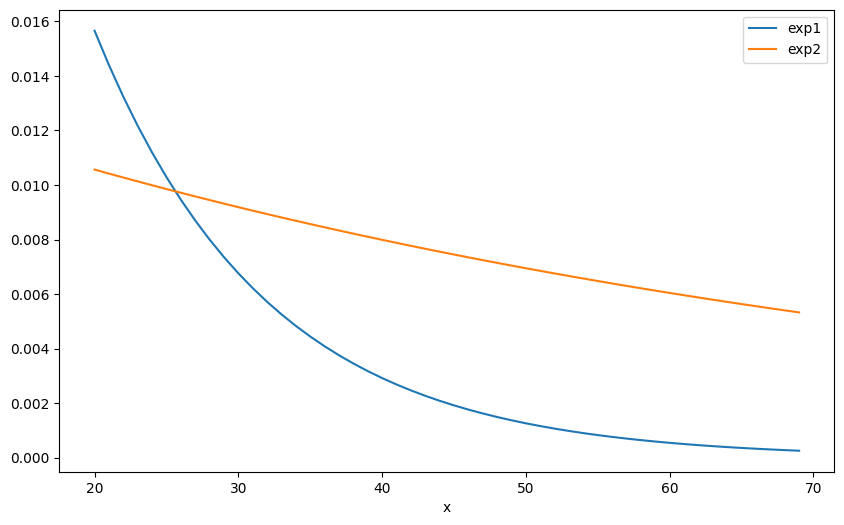

In [ ]:
from sklearn.neighbors import KernelDensity
import math
import matplotlib.pyplot as plt
from scipy.stats import expon

def fun_px(lmda, x):
    return lmda * math.exp(-lmda * x)

#Yunkang 5th run
lmda1 = mus[0]
lmda2 = mus[1]
# threshold = 33

rows = []
for x in range(20, 70):
    exp1 = fun_px(1/lmda1, x)
    exp2 = fun_px(1/lmda2, x)
    rows.append([x, exp1, exp2, exp1-exp2])
result_df = pd.DataFrame(rows, columns =['x', 'exp1', 'exp2', 'distance'])
print(result_df.head(15))
result_df.plot(x="x", y=["exp1", "exp2"],  figsize=(10, 6))
plt.show()

From the above plot, we see that the intersecting point for the two component is 26. We ran the model 5 times and found the average was 27 s and then used it as threshold.

We now show the Cumulative Distribution Function (CDF) of time data vs that of the mixture exponential model to see if we fitted the model well.

In [ ]:
df = pd.DataFrame(columns=['Theoretical','Empirical','Row'])
sub_df = pd.DataFrame(columns=['Theoretical','Empirical','Row'])

dataset = edge_count['mean_inter_share_time']

distributions = []
for j in range(len(mus)):
    distributions.append({"type": np.random.exponential, "kwargs": {"scale": mus[j]}})

coefficients = np.array(pis)
coefficients /= coefficients.sum()
sample_size = len(dataset)

num_distr = len(distributions)
data = np.zeros((sample_size, num_distr))

for idx, distr in enumerate(distributions):
    data[:, idx] = distr["type"](size=(sample_size,), **distr["kwargs"])
random_idx = np.random.choice(np.arange(num_distr), size=(sample_size,), p=coefficients)
sample = data[np.arange(sample_size), random_idx]

sub_df['Theoretical'] = sample
sub_df['Empirical'] = dataset + 0.00001
sub_df['Row'] = 0

df = pd.concat([df, sub_df])
# print(df)
fig = px.ecdf(df, log_x = True, facet_row='Row', template="simple_white")

fig.update_layout(xaxis_range=[0, 5], yaxis_range=[0,1])
fig.update_layout( # customize font and legend orientation & position
     legend=dict(
        title=None, orientation="h", y=1, yanchor="bottom", x=0.5, xanchor="center"
    )
)

fig.write_html('ecdf_emm.html')
IFrame(src='ecdf_emm.html', width=700, height=600)

/tmp/ipykernel_3468/627703950.py:26: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, sub_df])




### Identify Num of link shared threshold for coordination
1. Plot density plot on num of link shared to visualize the number of components
2. Use Negative Binomial Mixture Model to estimate the threshold for identifying coordinated vs organic share


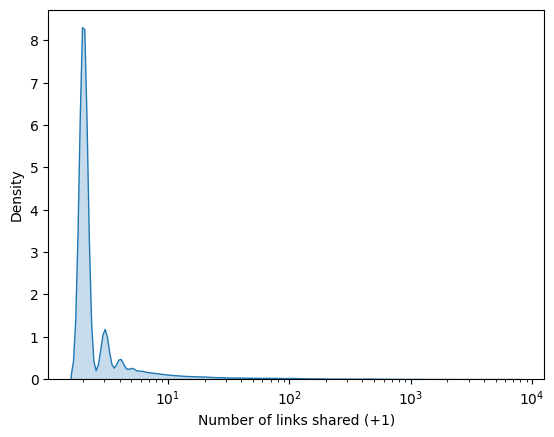

In [ ]:
freq_data = edge_count['num_of_share'].values + 1
# Vẽ theo trục x log; không lấy log10 hai lần.
sns.kdeplot(freq_data, log_scale=True, fill=True)
plt.xlabel('Number of links shared (+1)')
plt.show()

#### Fit neg-binomial mixture model in freq data

In [ ]:
def log_like_mix(alpha1, b1, alpha2, b2, w, n):
    """Log-likeihood of binary Negative Binomial mixture model."""
    # Fix nonidentifieability be enforcing values of w
    if w < 0 or w > 1:
        return -np.inf

    # Physical bounds on parameters
    if alpha1 < 0 or alpha2 < 0 or b1 < 0 or b2 < 0:
        return -np.inf

    logx1 = st.nbinom.logpmf(n, alpha1, 1/(1+b1))
    logx2 = st.nbinom.logpmf(n, alpha2, 1/(1+b2))

    # Multipliers for log-sum-exp
    lse_coeffs = np.tile([w, 1-w], [len(n), 1]).transpose()

    # log-likelihood for each measurement
    log_likes = scipy.special.logsumexp(np.vstack([logx1, logx2]), axis=0, b=lse_coeffs)

    return np.sum(log_likes)

def log_like_iid_nbinom(params, n):
    """Log likelihood for i.i.d. NBinom measurements, parametrized by alpha, b=1/beta."""
    alpha, b = params

    if alpha <= 0 or b <= 0:
        return -np.inf

    return np.sum(st.nbinom.logpmf(n, alpha, 1/(1+b)))


def mle_iid_nbinom(n):
    """Perform maximum likelihood estimates for parameters for i.i.d. NBinom measurements, parametrized by alpha, b=1/beta"""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        res = scipy.optimize.minimize(
            fun=lambda params, n: -log_like_iid_nbinom(params, n),
            x0=np.array([3, 3]),
            args=(n,),
            method='Powell'
        )

    if res.success:
        return res.x
    else:
        raise RuntimeError('Convergence failed with message', res.message)

def initial_guess_mix(n, w_guess):
    """Generate initial guess for mixture model."""
    n_low = n[n < np.percentile(n, 100*w_guess)]
    n_high = n[n >= np.percentile(n, 100*w_guess)]

    alpha1, b1 = mle_iid_nbinom(n_low)
    alpha2, b2 = mle_iid_nbinom(n_high)

    return alpha1, b1, alpha2, b2


def mle_mix(n, w_guess):
    """Obtain MLE estimate for parameters for binary mixture
    of Negative Binomials."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        res = scipy.optimize.minimize(
            fun=lambda params, n: -log_like_mix(*params, n),
            x0=[*initial_guess_mix(n, w_guess), w_guess],
            args=(n,),
            method='Powell',
            tol=1e-4,
        )

    if res.success:
        return res.x
    else:
        raise RuntimeError('Convergence failed with message', res.message)


In [ ]:
dataset = edge_count['num_of_share'].values

# Guess for w
w_guess = 0.99

popt = mle_mix(dataset, w_guess)
alpha1, b1, alpha2, b2, w = popt
# Check out optimal parameters
print('alpha1 = {0:f}\nb1 = {1:f}\nalpha2 = {2:f}\nb2 = {3:f}\nw = {4:f}'.format(*popt))

alpha1 = 48.440355
b1 = 0.027709
alpha2 = 0.461302
b2 = 134.670190
w = 0.904370


#### Identify the threshold where the first component and the second component intersect

     x  nbinom1  nbinom2  distance
0    1    34.75     4.75  0.299966
1    2    23.16     3.45  0.197138
2    3    10.50     2.81  0.076920
3    4     3.64     2.41  0.012289
4    5     1.03     2.14 -0.011066
5    6     0.25     1.93 -0.016828
6    7     0.05     1.77 -0.017165
7    8     0.01     1.64 -0.016274
8    9     0.00     1.53 -0.015261
9   10     0.00     1.43 -0.014346
10  11     0.00     1.35 -0.013545
11  12     0.00     1.28 -0.012842
12  13     0.00     1.22 -0.012219
13  14     0.00     1.17 -0.011662
14  15     0.00     1.12 -0.011160
15  16     0.00     1.07 -0.010705
16  17     0.00     1.03 -0.010289
17  18     0.00     0.99 -0.009908
18  19     0.00     0.96 -0.009556


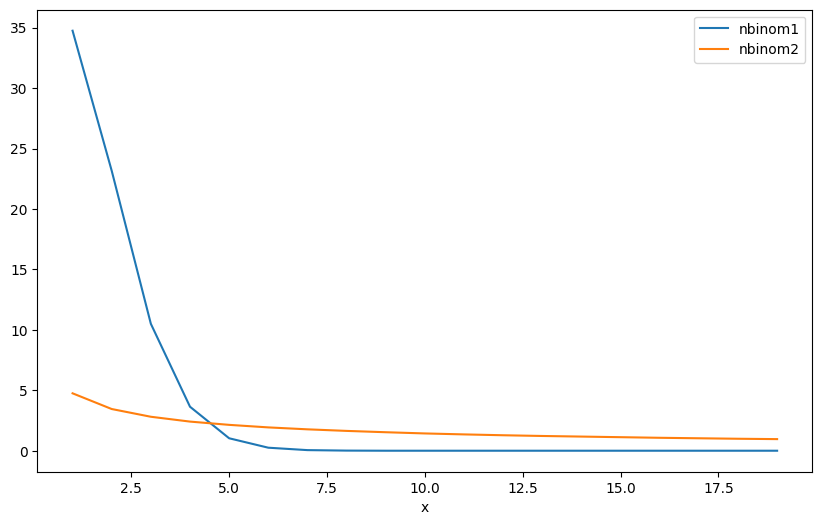

In [ ]:
rows = []
for x in range(1, 20):
    nbinom1 = stats.nbinom.pmf(x, alpha1, 1/(1+b1))
    nbinom2 = stats.nbinom.pmf(x, alpha2, 1/(1+b2))
#     print(x, " & ", round(nbinom1*100, 2), " & ", round(nbinom2*100, 2), "\\\\")
    rows.append([x, round(nbinom1*100, 2), round(nbinom2*100, 2), nbinom1-nbinom2])
result_df = pd.DataFrame(rows, columns =['x', 'nbinom1', 'nbinom2', 'distance'])
print(result_df)
result_df.plot(x="x", y=["nbinom1", "nbinom2"],  figsize=(10, 6))
plt.show()

The intersecting point for the two component is 4. But we used 9 as threshold -- as a more conservative estimate -- because the probability of organically sharing (i.e., the first component) falls to zero at 9 URLs.
Hence, final threshold is 9.

We now show the Cumulative Distribution Function (CDF) of frequency data vs that of the mixture negative binomial model to see if we fitted the model well.

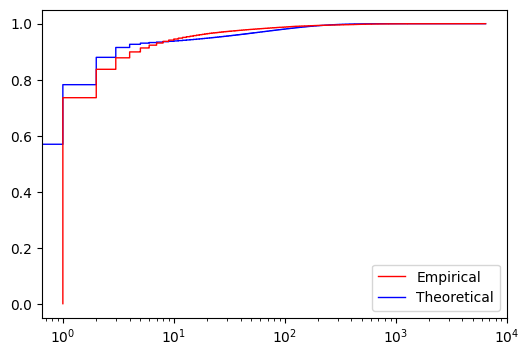

In [ ]:
n = dataset

# Simple ecdf function
def ecdf(x):
    sx = np.sort(x)
    n = sx.size
    sy = np.arange(1, n+1)/n
    return sx,sy

# CDF for theoritical data
n_emperical, cdf_emperical = ecdf(n)

fig, ax = plt.subplots(figsize=(6,4))
ax.step(n_emperical, cdf_emperical, color='red', label='Empirical',
        linewidth=1, zorder=3)

n_theor = np.arange(0, n.max()+1)
cdf_theor = w * st.nbinom.cdf(n_theor, alpha1, 1/(1+b1))
cdf_theor += (1 - w) * st.nbinom.cdf(n_theor, alpha2, 1/(1+b2))

ax.step(n_theor, cdf_theor, color='blue', linewidth = 1,
        label='Theoretical', zorder = 2)
ax.legend(loc='lower right')
# ax.set_xlim(-5, 300)
ax.set_xscale('log')
plt.show()

### Find Coordination
1. Use the threshold identified above to find different type of coordination.

In [ ]:
time_threshold = 27
freq_threshold = 9
fast_sharing_pages = []
repetitive_sharing_pages = []
mix_sharing_pages = []

m_count = 0
f_count = 0
r_count = 0

m_link = 0
f_link = 0
r_link = 0

m_time = 0
f_time = 0
r_time= 0

for i, row in edge_count.iterrows():
    s_time = row['mean_inter_share_time']
    n_url = row['num_of_share']
    u = row['Source']
    v = row['Target']
    if s_time <= time_threshold and n_url >= freq_threshold: #mix (Green)
        m_link += n_url
        m_count += 1
        m_time += s_time
        if u not in mix_sharing_pages:
            mix_sharing_pages.append(u)
        if v not in mix_sharing_pages:
            mix_sharing_pages.append(v)
    elif n_url >= freq_threshold: # Repetative
        r_count += 1
        r_link += n_url
        r_time += s_time
        if u not in repetitive_sharing_pages:
            repetitive_sharing_pages.append(u)
        if v not in repetitive_sharing_pages:
            repetitive_sharing_pages.append(v)
    elif s_time <= time_threshold and n_url >= 2: #fast
        f_count += 1
        f_link += n_url
        f_time += s_time
        if u not in fast_sharing_pages:
            fast_sharing_pages.append(u)
        if v not in fast_sharing_pages:
            fast_sharing_pages.append(v)

In [ ]:
totalp = 16169
totalu = 11248706

print("Type         Pages                Links             Avg. Time      Avg. Link")
print("_____________________________________________________________________________________")
print("Fast Sharing        ", len(fast_sharing_pages), "({:.2f}\%)".format((len(fast_sharing_pages)/totalp)*100), "       " , f_link, "({:.2f}\%)".format((f_link/totalu)*100), "      ", "{:.2f} sec".format(f_time/f_count), "      ", "{:.2f}".format(f_link/f_count))
print("Repetitive Sharing  ", len(repetitive_sharing_pages), "({:.2f}\%)".format((len(repetitive_sharing_pages)/totalp)*100), "     " , r_link, "({:.2f}\%)".format((r_link/totalu)*100), "    ", "{:.2f} sec".format(r_time/r_count),"    ", "{:.2f}".format(r_link/r_count))
print("Mix Sharing         ", len(mix_sharing_pages), "({:.2f}\%)".format((len(mix_sharing_pages)/totalp)*100), "       " , m_link, "({:.2f}\%)".format((m_link/totalu)*100), "    ", "{:.2f} sec".format(m_time/m_count),"    ", "{:.2f}".format(m_link/m_count))

print("\n\n")
coordination_pages = (mix_sharing_pages + fast_sharing_pages + repetitive_sharing_pages)
print("Total Pages involved in Coordination: ", len(set(coordination_pages)), "{:.2f}".format((len(set(coordination_pages))/totalp)*100))
cordinated_link = m_link+f_link+r_link
print("Total links: ", cordinated_link, "{:.2f}".format((cordinated_link/totalu)*100))

Type         Pages                Links             Avg. Time      Avg. Link
_____________________________________________________________________________________
Fast Sharing         658 (4.07\%)         4793 (0.04\%)        5.22 sec        3.56
Repetitive Sharing   3309 (20.47\%)       494048 (4.39\%)      7828.69 sec      82.18
Mix Sharing          433 (2.68\%)         118769 (1.06\%)      8.60 sec      184.42



Total Pages involved in Coordination:  3705 22.91
Total links:  617610 5.49


<>:6: SyntaxWarning:

invalid escape sequence '\%'

<>:6: SyntaxWarning:

invalid escape sequence '\%'

<>:7: SyntaxWarning:

invalid escape sequence '\%'

<>:7: SyntaxWarning:

invalid escape sequence '\%'

<>:8: SyntaxWarning:

invalid escape sequence '\%'

<>:8: SyntaxWarning:

invalid escape sequence '\%'

<>:6: SyntaxWarning:

invalid escape sequence '\%'

<>:6: SyntaxWarning:

invalid escape sequence '\%'

<>:7: SyntaxWarning:

invalid escape sequence '\%'

<>:7: SyntaxWarning:

invalid escape sequence '\%'

<>:8: SyntaxWarning:

invalid escape sequence '\%'

<>:8: SyntaxWarning:

invalid escape sequence '\%'

/tmp/ipykernel_3468/3647019233.py:6: SyntaxWarning:

invalid escape sequence '\%'

/tmp/ipykernel_3468/3647019233.py:6: SyntaxWarning:

invalid escape sequence '\%'

/tmp/ipykernel_3468/3647019233.py:7: SyntaxWarning:

invalid escape sequence '\%'

/tmp/ipykernel_3468/3647019233.py:7: SyntaxWarning:

invalid escape sequence '\%'

/tmp/ipykernel_3468/3647019233.py:8: SyntaxW

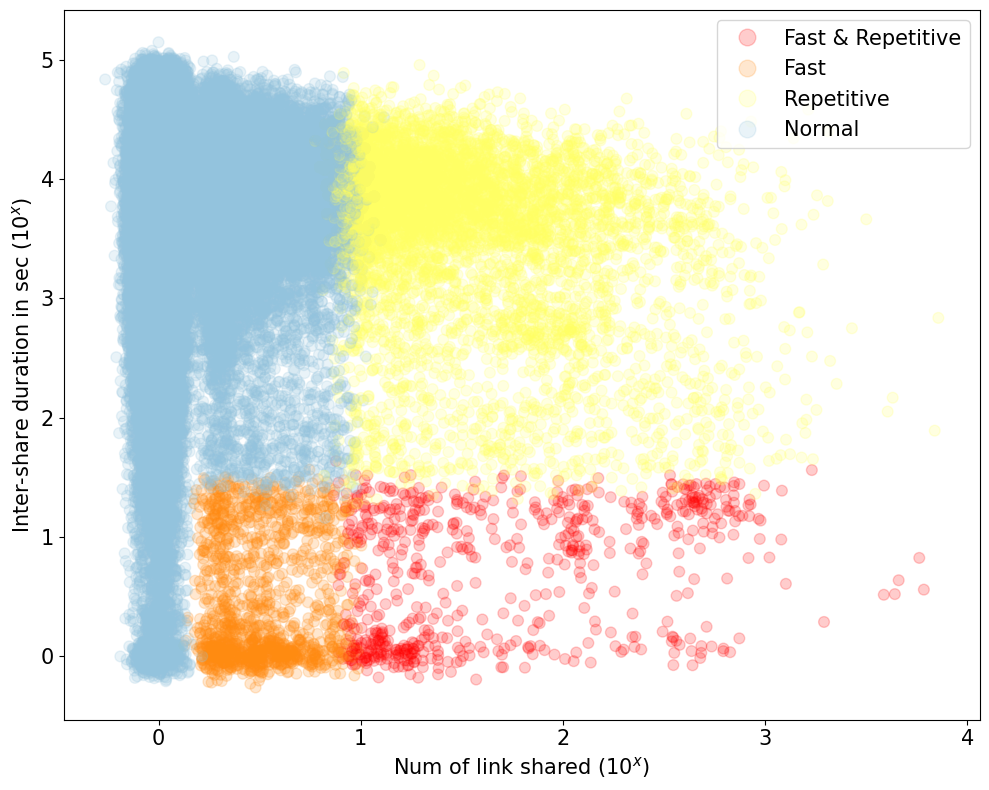

In [ ]:
%matplotlib inline
import mpld3
import math
from matplotlib.colors import ListedColormap

colours = ListedColormap(['#FF0000', '#FF8B11','#FFFF64', '#93C3DD'])  #['#FF0000', '#FF8B11', '#FF8085', '#93C3DD'])#  '#13EAc9'
def rand_jitter(arr):
    stdev = .015 * (max(arr) - min(arr))
    return arr + np.random.randn(len(arr)) * stdev

def jitter(x, y, c, s=60, marker='o', cmap=None, norm=None, vmin=None, vmax=None, alpha=None, linewidths=None, verts=None, hold=None, **kwargs):
    return plt.scatter(rand_jitter(x), rand_jitter(y), s=s, c=c, marker=marker, cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, alpha=alpha, linewidths=linewidths, **kwargs)

share_time = []
url_count = []
dot_label = []
dot_colors = []

for i, row in edge_count.iterrows():
    s_time = row['mean_inter_share_time']
    n_url = row['num_of_share']
    u = row['Source']
    v = row['Target']
    if 1 == 1:
        share_time.append(math.log10(abs(s_time)+1))
        url_count.append(math.log10(n_url))
        if s_time <= time_threshold and n_url >= freq_threshold: #mix
            dot_colors.append(0)
        elif n_url >= freq_threshold: #repetitive
            dot_colors.append(2)
        elif s_time <= time_threshold and n_url >= 2: #fast
            dot_colors.append(1)
        else: #norm
            dot_colors.append(3)


classes = ['Fast & Repetitive', 'Fast', 'Repetitive', 'Normal']
fig = plt.figure(figsize=(10, 8))

scatter = jitter(url_count, share_time, c = dot_colors, alpha=0.2, cmap=colours)
plt.legend(handles=scatter.legend_elements()[0], labels=classes, fontsize = 15, markerscale=2., frameon=True, loc=1)
plt.grid(False)
plt.rcParams['axes.facecolor'] = '#D4D4D4'
plt.xlabel("Num of link shared ($10^x$)", fontsize = 15)
plt.ylabel("Inter-share duration in sec ($10^x$)", fontsize = 15)
plt.xticks(fontsize= 15)
plt.yticks(fontsize= 15)
plt.tight_layout()
plt.show()

In [ ]:
mix = []
fast = []
repetitive = []
for i, row in edge_count.iterrows():
    row_dict = {}
    s_time = row['mean_inter_share_time']
    n_url = row['num_of_share']
    row_dict['Source'] = row['Source']
    row_dict['Target'] = row['Target']
    row_dict['mean_inter_share_time'] = round(row['mean_inter_share_time'], 2)
    row_dict['num_of_share'] = row['num_of_share']
    if s_time <= time_threshold and n_url >= freq_threshold: #mix
        mix.append(row_dict)
    elif n_url >= freq_threshold: #repetitive
        repetitive.append(row_dict)
    elif s_time <= time_threshold and n_url >= 2: #fast
        fast.append(row_dict)
    else: #norm
        pass
fast_df = pd.DataFrame(fast)
repetitive_df = pd.DataFrame(repetitive)
mix_df = pd.DataFrame(mix)


#### Collect all coordinated sharing

In [ ]:
fast_df['type'] = 'Fast'
mix_df['type'] = 'Mixed'
repetitive_df['type'] = 'Repetitive'
cord_df = pd.concat([mix_df, fast_df, repetitive_df], ignore_index=True)

In [ ]:
page_color_list = ['#FF0000', '#FF8B11','#FFFF64', '#93C3DD']

def get_node_map(data_df):
    node_map = {}
    node_id = 0
    for index, row in data_df.iterrows():
        src = row.Source
        dst = row.Target
        if src not in node_map:
            node_map[src] = node_id
            node_id += 1
        if dst not in node_map:
            node_map[dst] = node_id
            node_id += 1
    return node_map

def get_edge_color(edges):
    edge_color = {}
    for i, row in edges.iterrows():
        key = (row['Source'], row['Target'])
        s_time = row['mean_inter_share_time']
        n_url = row['num_of_share']
        if s_time <= time_threshold and n_url >= freq_threshold: #mix
            edge_color[key] = '#FF0000'
        elif n_url >= freq_threshold: #repetitive
            edge_color[key] = '#FFFF64'
        elif s_time <= time_threshold and n_url >= 2: #fast
            edge_color[key] = '#FF8B11'
        else: #norm
            edge_color[key] = '#93C3DD'
    return edge_color

def get_page_color(node_map):
    page_color = {}
    for k, v in node_map.items():
        if k in mix_sharing_pages:
            page_color[k] = '#FF0000'
        elif k in repetitive_sharing_pages: #
            page_color[k] = '#FFFF64'
        elif k in fast_sharing_pages:
            page_color[k] = '#FF8B11'
        else: #gray
            page_color[k] = '#93C3DD'

    return page_color

def create_graph_df(df, node_map):
    G = nx.MultiGraph()
    #nodes
    for index, row in df.iterrows():
        src = row.Source
        target = row.Target
        G.add_node(src, name= src)
        G.add_node(target, name = target)
        s_time = row['mean_inter_share_time']
        n_url = row['num_of_share']
        color = '#93C3DD'
        if s_time <= time_threshold and n_url >= freq_threshold: #mix
            color = '#FF0000'
        elif n_url >= freq_threshold: #repetitive
            color = '#FFFF64'
        elif s_time <= time_threshold and n_url >= 2: #fast
            color = '#FF8B11'
        if color == '#93C3DD':
            G.add_edge(src, target, edge_color = color, weight=row.num_of_share, time = row.mean_inter_share_time, edge_alpha=0.3)
        else:
            G.add_edge(src, target, edge_color = color, weight=row.num_of_share, time = row.mean_inter_share_time, edge_alpha=1)
    print("Nodes :", len(G.nodes()), " Edges :", len(G.edges()))
    return G



# use df_cur = edge_count to generate Fig 1(b)
df_cur = edge_count[:2000]

node_map = get_node_map(df_cur)
node_list = [str(v) for k, v in node_map.items()]
print("Total Nodes: %s"%len(node_list))
G = create_graph_df(df_cur, node_map)

Total Nodes: 629
Nodes : 629  Edges : 2000


In [ ]:
net = Network(height="800px", width="1200px", notebook=True, directed=True, heading="Facebook Network")
net.force_atlas_2based(gravity=-50, central_gravity=0.01, spring_length=100, spring_strength=0.08, damping=0.4, overlap=0)

for n, data in G.nodes(data=True):
    net.add_node(n, shape='dot', size=10, color='#93C3DD', borderWidth = 1)
for u, v, data in G.edges(data=True):
    net.add_edge(u, v, value=0.0001*data['weight'], color= data['edge_color'], physics=True, alpha=data['edge_alpha'])
net.set_edge_smooth('dynamic')
# net.save_graph('test_2url.html')
net.show('test.html')

test.html


### Find 10 largest networks involved in different type of sharing

Table S10-12 in Supplementary material

In [ ]:
# df_cur = repetitive_df
df_cur = fast_df
# df_cur = mix_df

node_map = get_node_map(df_cur)
G = create_graph_df(df_cur, node_map)

networks = [G.subgraph(c).copy() for c in sorted(nx.connected_components(G), key=len, reverse=True)]
i = 1
for idx, net in enumerate(networks[:15]):

    total_edge = len(net.edges())
    stats = []
    stats.append("Total nodes: " + str(len(net.nodes())))
    stats.append("Total Edges: " + str(total_edge))
    stats.append("Link Shared: " + str(sum([data['weight'] for u, v, data in net.edges(data=True)])))
    stats.append("Avg. Time: " + str("{:.2f} sec".format(sum([data['time'] for u, v, data in net.edges(data=True)])/total_edge)))

    pages = [data['name'] for n, data in net.nodes(data=True)]
    print(str(i)+".", ', '.join(pages), ' \n'.join(stats))
    print('\n')
    i += 1


Nodes : 658  Edges : 1347
1. Lebanon Daily News, The Shreveport Times, Times Herald newspaper in Port Huron, Michigan, Asheville Citizen Times, The Augusta Chronicle, Green Bay Press-Gazette, Taunton Daily Gazette, Argus Leader Media, The Post-Crescent (Appleton-Fox Cities, Wisconsin), PackersNews, The Tuscaloosa News, SouthCoast Today, Pocono Record, Spartanburg Herald-Journal, Tennessean, NorthJersey.com, Battle Creek Enquirer, lohud, The Pueblo Chieftain, The Hornell Evening Tribune, Public Opinion, Courier & Press, Pacific Daily News, The Fayetteville Observer, Journal & Courier, The Daily News Journal - dnj.com, Savannah Morning News & SavannahNow.com, Seacoastonline.com, Manitowoc Herald Times Reporter, Kitsap Sun, Delmarva Now - Daily Times, The Commercial Appeal, The Columbus Dispatch, IndyStar, Athens Banner-Herald & OnlineAthens.com, StarNews, The Newport Daily News, Montgomery Advertiser, Tidesports.com, The Gaston Gazette, Monroe News, York Daily Record/Sunday News, Naples 

### Find domain used in coordination

- Find coordinated links with url
- Extract domain name from url

In [ ]:
# Chọn theo tên cột để không phụ thuộc vào thứ tự cột CSV.
data_subset = data_df[['Source', 'Target', 'URL']].copy()
data_subset.head(5)

,Source,Target,URL
0,BidenHarris2020,USVI Festivals,https://bideninaugural.org/watch/
1,USVI Festivals,Pro United Kingdom-Anti E.U.,https://bideninaugural.org/watch/
2,Pro United Kingdom-Anti E.U.,U.S. Congressman Henry Cuellar,https://bideninaugural.org/watch/
3,U.S. Congressman Henry Cuellar,Congresswoman Norma Torres,https://bideninaugural.org/watch/
4,Congresswoman Norma Torres,The Christian Left,https://bideninaugural.org/watch/


In [ ]:
mix_pages = mix_df.loc[:, ['Source', 'Target']]
mix_with_url = pd.merge(mix_pages, data_subset,  how='left', left_on=['Source','Target'], right_on = ['Source','Target'])
# mix_with_url = mix_with_url.sort_values(by='mean_share_time')
mix_with_url['type'] = 'Mixed'

fast_pages = fast_df.loc[:, ['Source', 'Target']]
fast_with_url = pd.merge(fast_pages, data_subset,  how='left', left_on=['Source','Target'], right_on = ['Source','Target'])
# fast_with_url = fast_with_url.sort_values(by='mean_share_time')
fast_with_url['type'] = 'Fast'

repetitive_pages = repetitive_df.loc[:, ['Source', 'Target']]
repetitive_with_url = pd.merge(repetitive_pages, data_subset,  how='left', left_on=['Source','Target'], right_on = ['Source','Target'])
# repetitive_with_url = repetitive_with_url.sort_values(by='mean_share_time')
repetitive_with_url['type'] = 'Repetitive'

In [ ]:
df_coordination = pd.concat(
    [mix_with_url, fast_with_url, repetitive_with_url], ignore_index=True
)
print('Coordinated shares:', len(df_coordination))
print(df_coordination.head(5))

Coordinated shares: 617610
         Source Target                                                URL  \
0  16 WAPT News   KCCI  https://www.wcvb.com/article/tail-waggin-reuni...   
1  16 WAPT News   KCCI  https://www.wesh.com/article/loud-boom-florida...   
2  16 WAPT News   KCCI  https://www.mynbc5.com/article/meet-the-vermon...   
3  16 WAPT News   KCCI  https://www.wyff4.com/article/coyote-makes-its...   
4  16 WAPT News   KCCI  https://www.wcvb.com/article/noise-complaint-l...   

    type  
0  Mixed  
1  Mixed  
2  Mixed  
3  Mixed  
4  Mixed  


#### Extract domain name from URL

In [ ]:
from tldextract import extract

def get_domain_name(url):
    result = extract(str(url))
    return result.top_domain_under_public_suffix or result.domain

df_coordination['domain_name'] = df_coordination['URL'].apply(get_domain_name)

In [ ]:
print("Total domain in engage in coordinations [%d]"%len(df_coordination['domain_name'].unique()))

Total domain in engage in coordinations [3264]


In [ ]:
data_df['domain_name'] = data_df['URL'].apply(get_domain_name)


In [ ]:
print("Total domain in our dataset [%d]"%len(data_df['domain_name'].unique()))

Total domain in our dataset [7447]


#### Top 400 domains

Table S9 in supplementary materials

In [ ]:
cordinated_domain = df_coordination.groupby(['domain_name']).agg({'domain_name':['count']}).reset_index()
cordinated_domain.columns = ['domain_name', 'num_of_link_shared']
cordinated_domain =  cordinated_domain.sort_values(by='num_of_link_shared', ascending=False)
cordinated_domain[:400]

,domain_name,num_of_link_shared
3047,wegotthiscovered.com,38647
30,7news.com.au,24566
1534,legit.ng,22387
91,adomonline.com,16469
2632,theepochtimes.com,12510
...,...,...
2875,tvline.com,190
221,augustachronicle.com,190
1605,magiccityweekend.com,188
2062,perezhilton.com,188


In [ ]:
type_domain = df_coordination.iloc[:,[3,4]]
type_domain = df_coordination.groupby(['type','domain_name']).agg({'domain_name':['nunique']}).reset_index()
type_domain.columns = ['type','domain_name', 'count']
type_domain = type_domain.groupby(['type']).agg({'domain_name':['count']}).reset_index()

df_coordination.groupby(['type','domain_name']).agg({'domain_name':['nunique']}).reset_index()
coordination_type_vs_domain = df_coordination.groupby(['type']).agg({'domain_name':['count']}).reset_index()
coordination_type_vs_domain.columns = ['type','num_of_share']
coordination_type_vs_domain  = coordination_type_vs_domain.sort_values(by='num_of_share', ascending=False)


#### Find domain black listed by Media Bias Fact Check

In [ ]:
import pandas as pd

rows = [
    ("Pages có co-sharing", 11542, 11542),
    ("Quan sát co-sharing", 880671, 880671),
    ("Pages phối hợp", 3705, 3705),
    ("Quan sát phối hợp", 617610, 617610),
]

report = pd.DataFrame(
    rows,
    columns=["Chỉ số", "Paper gốc", "Tái hiện"]
)

report["Chênh lệch"] = (
    report["Tái hiện"] - report["Paper gốc"]
)

report["Sai lệch (%)"] = (
    100 * report["Chênh lệch"].abs()
    / report["Paper gốc"]
).round(2)

report["Đánh giá"] = report["Chênh lệch"].apply(
    lambda x: "Khớp" if x == 0 else "Khác"
)

display(report)

report.to_csv(
    "/content/so_sanh_paper_facebook.csv",
    index=False,
    encoding="utf-8-sig"
)

,Chỉ số,Paper gốc,Tái hiện,Chênh lệch,Sai lệch (%),Đánh giá
0,Pages có co-sharing,11542,11542,0,0.0,Khớp
1,Quan sát co-sharing,880671,880671,0,0.0,Khớp
2,Pages phối hợp,3705,3705,0,0.0,Khớp
3,Quan sát phối hợp,617610,617610,0,0.0,Khớp


In [ ]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest

SEED = 42
MIN_SHARED_URLS = 2    # Chỉ tạo cạnh khi 2 trang cùng chia sẻ ít nhất 2 URL
FAST_SECONDS = 27      # Mốc tham chiếu paper; KHÔNG phải ngưỡng độc lập đã ước lượng
MIN_COMMUNITY_SIZE = 4
OUT = Path('/content/FB_CoGAD_Results') if Path('/content').exists() else Path('FB_CoGAD_Results')
OUT.mkdir(parents=True, exist_ok=True)

if 'data_df' in globals() and {'Source','Target','URL','delta'}.issubset(data_df.columns):
    df = data_df[['Source','Target','URL','delta']].copy()
    print('Sử dụng data_df có sẵn trong notebook Facebook')
else:
    paths = [Path('/content/dataverse_files/fb_sharing.csv'), Path('/content/fb_sharing.csv'), Path('fb_sharing.csv')]
    csv_path = next((p for p in paths if p.is_file()), None)
    if csv_path is None:
        raise FileNotFoundError('Không thấy fb_sharing.csv. Đặt tại /content/dataverse_files/fb_sharing.csv hoặc chạy sau ô data_df trong notebook Facebook.')
    df = pd.read_csv(csv_path, usecols=['Source','Target','URL','delta'])
    print('Đọc:', csv_path)

n_initial = len(df)
missing_rows = int(df[['Source','Target','URL','delta']].isna().any(axis=1).sum())
df = df.dropna(subset=['Source','Target','URL','delta']).copy()
df['delta'] = pd.to_numeric(df['delta'], errors='coerce')
negative_rows = int((df['delta'] < 0).sum())
df = df[df['delta'].notna() & (df['delta'] >= 0)].copy()
for c in ['Source','Target','URL']:
    df[c] = df[c].astype(str).str.strip()
self_rows = int((df.Source == df.Target).sum())
df = df[(df.Source != '') & (df.Target != '') & (df.Source != df.Target)]
print(f'Dữ liệu: {len(df):,}/{n_initial:,} dòng được dùng; {pd.unique(pd.concat([df.Source,df.Target],ignore_index=True)).size:,} Pages')
print(f'Đã loại: {missing_rows:,} dòng thiếu, {negative_rows:,} delta âm, {self_rows:,} Source = Target. Các thống kê sau lọc KHÔNG so sánh trực tiếp với paper gốc.')

Sử dụng data_df có sẵn trong notebook Facebook
Dữ liệu: 757,897/880,671 dòng được dùng; 10,724 Pages
Đã loại: 0 dòng thiếu, 48 delta âm, 122,726 Source = Target. Các thống kê sau lọc KHÔNG so sánh trực tiếp với paper gốc.


In [ ]:
# Ô 2/4 — Tổng hợp các cạnh và xây dựng Coordination Graph
# Quy ước đồ thị vô hướng: hai trang (A,B) tương đương (B,A)
s = df['Source'].to_numpy(dtype=str)
t = df['Target'].to_numpy(dtype=str)
df['page_a'] = np.where(s <= t, s, t)
df['page_b'] = np.where(s <= t, t, s)
df['fast_event'] = (df.delta <= FAST_SECONDS).astype('int8')

pairs = (df.groupby(['page_a','page_b'], sort=False)
           .agg(n_events=('URL','size'), n_urls=('URL','nunique'),
                fast_ratio=('fast_event','mean'), median_delta=('delta','median'))
           .reset_index())
pairs = pairs[pairs.n_urls >= MIN_SHARED_URLS].copy().reset_index(drop=True)
if pairs.empty:
    raise RuntimeError('Không có cặp nào cùng chia sẻ >=2 URL. Hãy giảm MIN_SHARED_URLS.')
pairs['weight'] = np.log1p(pairs.n_urls) * (1.0 + pairs.fast_ratio)
pairs['log_urls'] = np.log1p(pairs.n_urls)

G = nx.Graph()
G.add_weighted_edges_from(pairs[['page_a','page_b','weight']].itertuples(index=False, name=None))
print(f'Graph: {G.number_of_nodes():,} Pages; {G.number_of_edges():,} Edges')
print('Phát hiện cộng đồng Louvain...')
comms = nx.community.louvain_communities(G, weight='weight', seed=SEED)
node_to_group = {node: i for i, nodes in enumerate(comms) for node in nodes}
pairs['group_a'] = pairs.page_a.map(node_to_group)
pairs['group_b'] = pairs.page_b.map(node_to_group)
internal = pairs[pairs.group_a == pairs.group_b].copy()
internal['group_id'] = internal.group_a.astype(int)
print('Số cộng đồng Louvain:', len(comms))

Graph: 7,368 Pages; 25,237 Edges
Phát hiện cộng đồng Louvain...
Số cộng đồng Louvain: 509


In [ ]:
# Ô 3/4 — Multi-view Group Anomaly Detection
# Ba nguồn đặc trưng: cấu trúc mạng, hành vi chia sẻ URL, thời gian phối hợp.
agg = (internal.groupby('group_id', sort=False)
       .agg(internal_edges=('weight','size'),
            avg_weight=('weight','mean'),
            avg_shared_urls=('n_urls','mean'),
            fast_ratio=('fast_ratio','mean'),
            median_delta=('median_delta','median')))
rows = []
for gid, members in enumerate(comms):
    n = len(members)
    if gid not in agg.index or n < MIN_COMMUNITY_SIZE:
        continue
    v = agg.loc[gid]
    edge_n = int(v.internal_edges)
    rows.append({'group_id':gid,'num_pages':n,'internal_edges':edge_n,
                 'density':2*edge_n/(n*(n-1)),
                 'avg_degree':2*edge_n/n,
                 'avg_weight':float(v.avg_weight),
                 'avg_shared_urls':float(v.avg_shared_urls),
                 'fast_ratio':float(v.fast_ratio),
                 'median_delta_sec':float(v.median_delta)})
groups = pd.DataFrame(rows)
if len(groups) < 3:
    raise RuntimeError('Quá ít cộng đồng >=4 Pages để xếp hạng. Giảm MIN_COMMUNITY_SIZE xuống 3 rồi chạy lại ô này.')

# Điểm theo từng view: cao = nhiều tín hiệu bất thường / phối hợp
# Ghi chú: score chỉ thể hiện mức độ khác biệt, KHÔNG phải xác suất gây hại.
groups['temporal_score'] = groups['fast_ratio'].rank(pct=True)
groups['behavior_score'] = groups['avg_shared_urls'].rank(pct=True)
groups['structural_score'] = (0.6*groups['density'].rank(pct=True) +
                              0.4*groups['avg_degree'].rank(pct=True))
features = groups[['density','avg_degree','avg_weight','avg_shared_urls','fast_ratio','median_delta_sec']].copy()
features['median_delta_sec'] = np.log1p(features['median_delta_sec'])
features = features.replace([np.inf,-np.inf],np.nan).fillna(features.median(numeric_only=True))
X = RobustScaler().fit_transform(features)
iso = IsolationForest(n_estimators=120, contamination='auto', random_state=SEED, n_jobs=-1)
groups['isolation_raw'] = -iso.fit(X).score_samples(X)
groups['isolation_score'] = groups['isolation_raw'].rank(pct=True)
groups['CoGAD_MV_score'] = (0.25*groups['temporal_score'] +
                             0.25*groups['behavior_score'] +
                             0.25*groups['structural_score'] +
                             0.25*groups['isolation_score'])
groups = groups.sort_values('CoGAD_MV_score', ascending=False).reset_index(drop=True)
groups['example_pages'] = groups['group_id'].apply(
    lambda i:'; '.join(sorted(comms[int(i)])[:5]))
show_cols = ['group_id','num_pages','internal_edges','density','fast_ratio',
             'avg_shared_urls','median_delta_sec','CoGAD_MV_score','example_pages']
print('Top 10 nhóm cần ưu tiên xem xét (CHƯA phải nhóm độc hại):')
display(groups[show_cols].head(10).round(4))

# Ablation mô tả: so sánh mức trùng top-10 khi bỏ từng view. Không phải metric có nhãn.
views={'Full': ['temporal_score','behavior_score','structural_score','isolation_score'],
       'No temporal':['behavior_score','structural_score','isolation_score'],
       'No behavioral':['temporal_score','structural_score','isolation_score'],
       'No structural':['temporal_score','behavior_score','isolation_score']}
full_top=set(groups.head(10).group_id)
ablation_rows = []
for name, fs in views.items():
    ids=set(groups.assign(score=groups[fs].mean(axis=1)).nlargest(10,'score').group_id)
    overlap=len(ids & full_top)
    ablation_rows.append({'variant':name,'top10_overlap_with_full':overlap})
    print(f'Top-10 overlap ({name}): {overlap}/10')
ablation = pd.DataFrame(ablation_rows)

Top 10 nhóm cần ưu tiên xem xét (CHƯA phải nhóm độc hại):


,group_id,num_pages,internal_edges,density,fast_ratio,avg_shared_urls,median_delta_sec,CoGAD_MV_score,example_pages
0,8,9,36,1.0,0.8006,924.7778,6.00,0.9572,Addicted 2 Country Music; Classic Country Musi...
1,30,4,6,1.0,0.9987,800.0000,0.00,0.9192,POPxo; POPxo Beauty; POPxo Fashion; POPxo Wedding
2,12,8,28,1.0,0.6032,225.3929,0.75,0.8848,Animal Rescue Home; Animal Rescue Stories; Goo...
3,19,5,10,1.0,0.9009,220.7000,7.50,0.8779,DailyMore; DogsWoofs; PitBulls House; Puppies ...
4,199,10,36,0.8,0.6568,340.0278,13.50,0.8650,Black Adam Schefter; Black Skip Bayless; Cryin...
5,24,4,6,1.0,0.6274,430.0000,4.00,0.8504,iNFOnews Kamloops; iNFOnews Kelowna; iNFOnews ...
6,29,4,6,1.0,0.5516,437.0000,25.25,0.8286,Land of 10; Michigan Wolverines - Land of 10; ...
7,315,5,10,1.0,1.0000,42.5000,0.00,0.8272,Did You Know?; I Am A Child of God; I Love God...
8,33,4,6,1.0,0.6075,361.3333,17.00,0.8051,Bidemi Kosoko; Fans Of Muyiwa Ademola; Fans of...
9,227,4,6,1.0,1.0000,49.6667,0.00,0.7942,I Bet Jesus Can Break The Record For Most Fans...


Top-10 overlap (Full): 10/10
Top-10 overlap (No temporal): 7/10
Top-10 overlap (No behavioral): 7/10
Top-10 overlap (No structural): 7/10


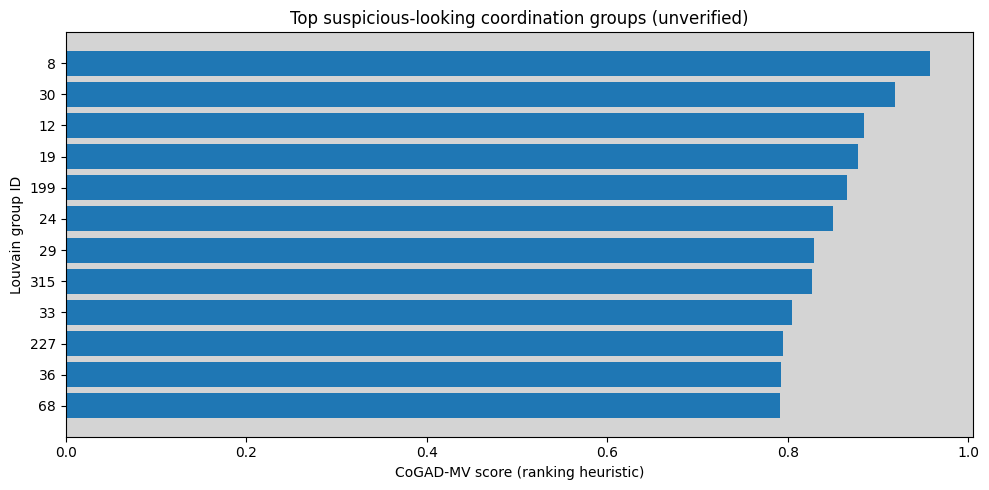

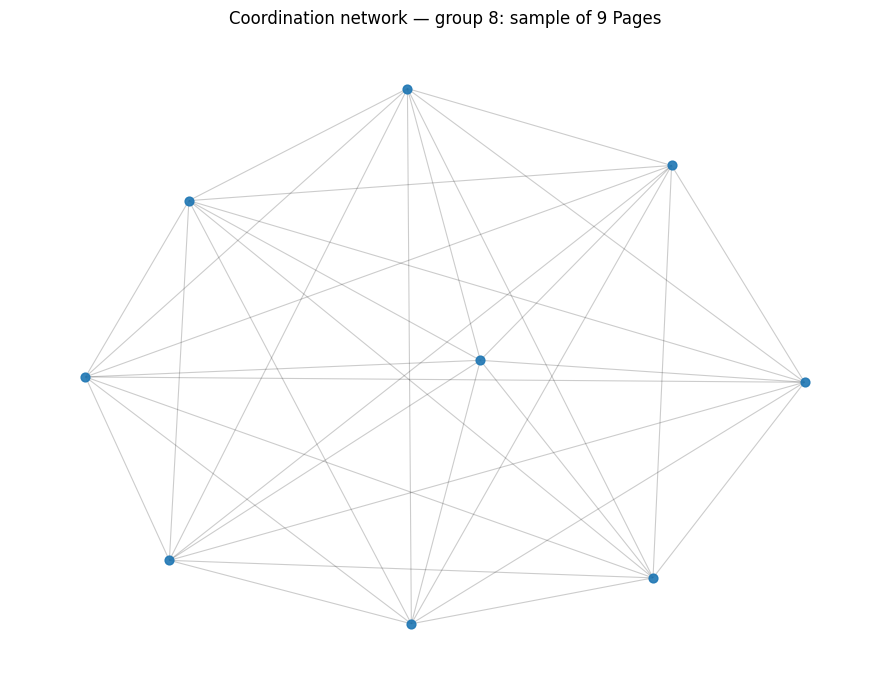

Đã lưu: /content/FB_CoGAD_MV_Quick_Results.zip
Dữ liệu nhãn gốc: chưa có. Không báo cáo Accuracy/F1/AUC hay tuyên bố vượt paper.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Ô 4/4 — Lưu CSV, biểu đồ và tải kết quả
from zipfile import ZipFile, ZIP_DEFLATED

edge_export = pairs[['page_a','page_b','n_events','n_urls','fast_ratio','median_delta','weight','group_a','group_b']]
edge_export.to_csv(OUT/'graph_edges.csv', index=False, encoding='utf-8-sig')
groups.to_csv(OUT/'group_anomaly_ranking.csv', index=False, encoding='utf-8-sig')
ablation.to_csv(OUT/'ablation_top10_overlap.csv',index=False,encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(10,5))
top = groups.head(12).iloc[::-1]
ax.barh(top.group_id.astype(str), top.CoGAD_MV_score)
ax.set(xlabel='CoGAD-MV score (ranking heuristic)',ylabel='Louvain group ID',title='Top suspicious-looking coordination groups (unverified)')
fig.tight_layout();fig.savefig(OUT/'top_group_scores.png',dpi=170);plt.show()

# Trực quan hóa nhóm đứng đầu, giới hạn số nút/cạnh cho slide
winner = int(groups.iloc[0].group_id)
nodes = sorted(comms[winner])[:70]
sub = G.subgraph(nodes).copy()
if sub.number_of_edges() > 600:
    selected = sorted(sub.edges(data=True), key=lambda e:e[2].get('weight',1),reverse=True)[:600]
    H=nx.Graph();H.add_nodes_from(sub.nodes());H.add_edges_from(selected);sub=H
fig,ax=plt.subplots(figsize=(9,7))
pos=nx.spring_layout(sub, seed=SEED, iterations=40, weight='weight')
nx.draw_networkx_edges(sub,pos,ax=ax,alpha=.20,width=.8)
nx.draw_networkx_nodes(sub,pos,ax=ax,node_size=40,node_color='tab:blue',alpha=.9)
ax.set_title(f'Coordination network — group {winner}: sample of {len(nodes)} Pages')
ax.axis('off');fig.tight_layout();fig.savefig(OUT/'top_group_network.png',dpi=170);plt.show()

metadata={'data_rows':int(len(df)),'graph_nodes':G.number_of_nodes(),
 'graph_edges':G.number_of_edges(),'louvain_communities':len(comms),
 'ranked_communities':len(groups), 'min_shared_urls':MIN_SHARED_URLS,
 'fast_seconds_reference':FAST_SECONDS,'random_seed':SEED,
 'caveat':'Unsupervised prototype; no independent ground-truth labels, no measured improvement over original paper.'}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
zip_path = OUT.parent / 'FB_CoGAD_MV_Quick_Results.zip'
with ZipFile(zip_path,'w',ZIP_DEFLATED) as z:
    for p in OUT.iterdir(): z.write(p,arcname=p.name)
print('Đã lưu:',zip_path)
print('Dữ liệu nhãn gốc: chưa có. Không báo cáo Accuracy/F1/AUC hay tuyên bố vượt paper.')
if Path('/content').exists():
    try:
        from google.colab import files
        files.download(str(zip_path))
    except Exception as exc:
        print('Có thể tải bằng Files ở thanh bên Colab:',exc)
